# Técnicas para oráculos — `oracle_prompt.png`

Mesmo gráfico de `graphic/oracle/grafico_tecnicas_prompt_oracle.ipynb`. Os números vêm de `../data/tabela_de_codigos.csv`: técnicas de prompt (PE) e de fine-tuning (FT) dos estudos com a atividade A6. Um estudo pode usar mais de uma técnica.

In [1]:
import sys
sys.path.insert(0, "../scripts")   # graficos/scripts: dados_artefatos.py, paleta_grupos.py

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import dados_artefatos as da
from paleta_grupos import tons_grupo, CINZA_OUTROS, CINZA_INDEFINIDO

# família laranja do grupo oracle: prompt engineering num tom escuro, fine-tuning num tom claro
_tons = tons_grupo("oracle", 5)
cor_elaborada = _tons[3]
cor_finetuning = _tons[1]
cor_fixo = CINZA_INDEFINIDO   # "Undefined" / "Unspecified"

In [2]:
rotulos_pe = {"PE6": "Structured\ntemplate", "PE2": "Zero-shot", "PE1": "Few-shot", "PE5": "Iterative\nrefinement",
              "PE4": "Role prompting", "PE3": "Chain-of-thought", "PE8": "Prompt-chaining", "PE7": "RAG",
              "PE9": "ReAct", "PE10": "Tree-of-thought", "PE11": "Undefined"}
rotulos_ft = {"FT1": "Supervised", "FT3": "LoRA", "FT2": "QLoRA", "FT4": "Reinforcement\nlearning", "FT5": "Unspecified"}

pe, ft, n_estudos, n_finetuning = da.tecnicas("A6")

def barras(contagem, rotulos, indefinido, cor):
    """Barras em ordem decrescente, sem as técnicas com zero estudos; a indefinida vai no fim, em cinza."""
    ordem = sorted([c for c in rotulos if c != indefinido and contagem[c] > 0], key=lambda c: -contagem[c])
    ordem += [indefinido] if contagem[indefinido] > 0 else []
    return [{"tipo": rotulos[c], "valor": int(contagem[c]), "cor": cor_fixo if c == indefinido else cor} for c in ordem]

dados = barras(pe, rotulos_pe, "PE11", cor_elaborada)
finetuning = barras(ft, rotulos_ft, "FT5", cor_finetuning)
print(n_estudos, "estudos;", n_finetuning, "com fine-tuning")

# espaço de uma barra entre prompt engineering e fine-tuning
x_pos = list(range(len(dados))) + [len(dados) + 1 + i for i in range(len(finetuning))]
todos = dados + finetuning

90 estudos; 9 com fine-tuning


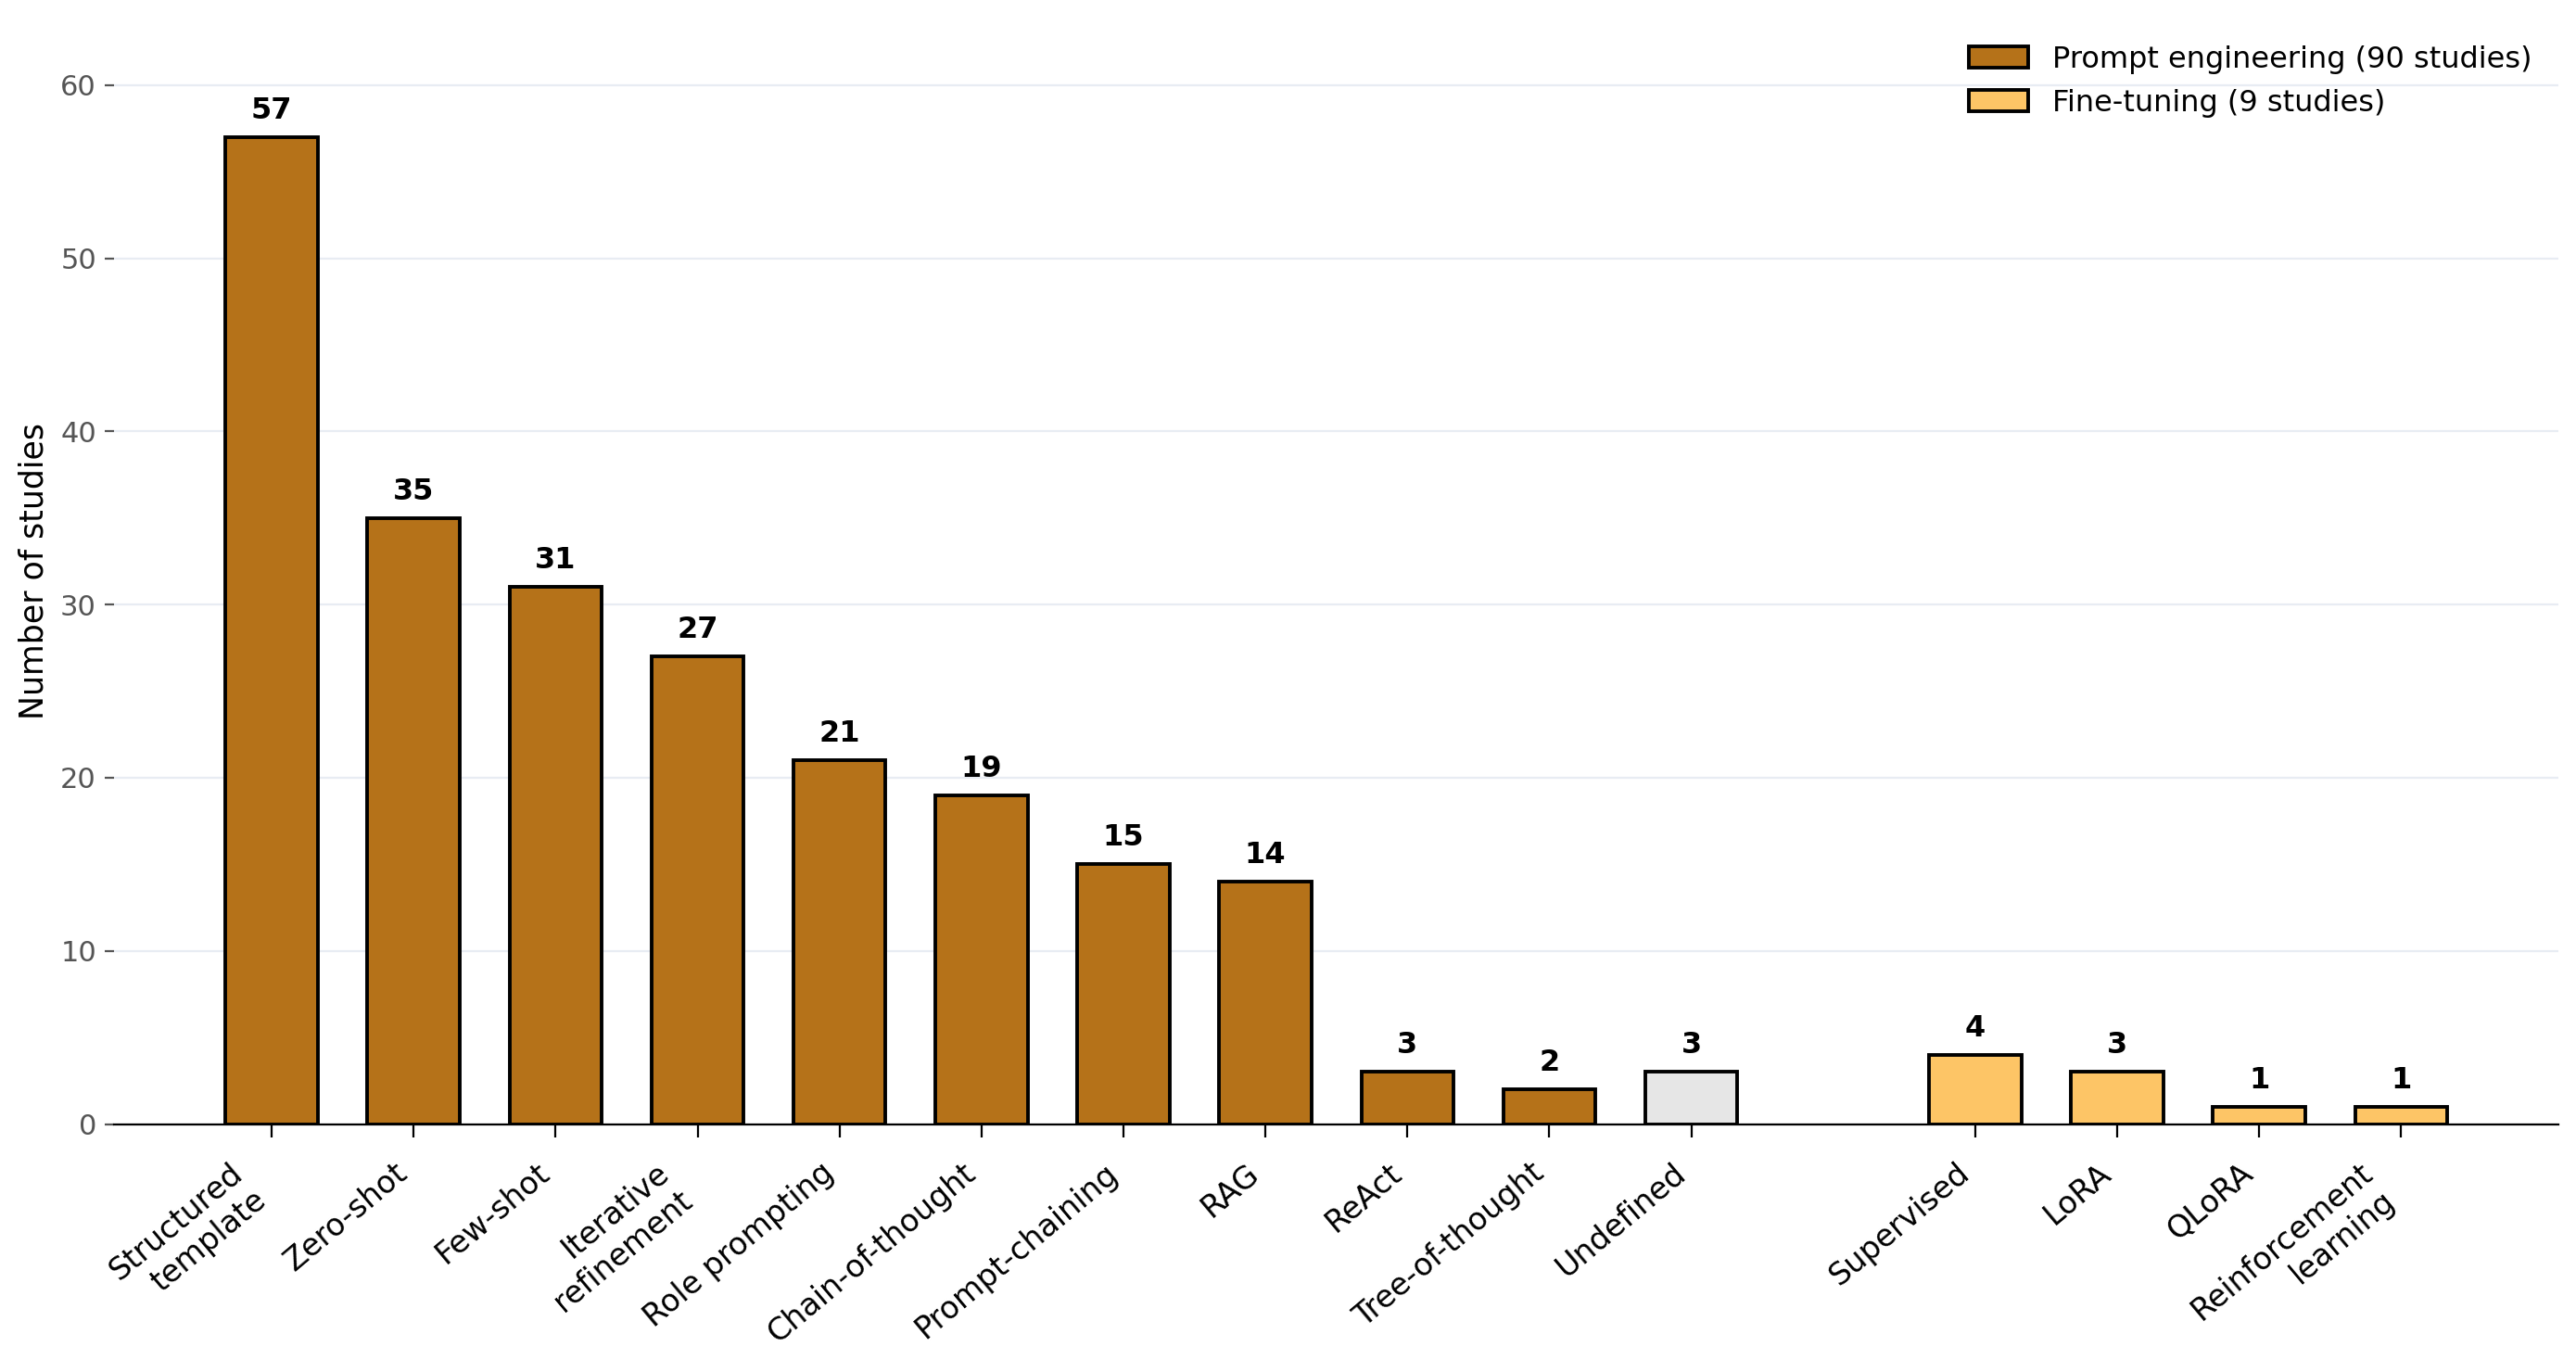

In [3]:
fig, ax = plt.subplots(figsize=(14, 7.5), dpi=200)

for x, d in zip(x_pos, todos):
    ax.bar(x, d["valor"], color=d["cor"], width=0.65, edgecolor="black", linewidth=1.4, zorder=3)
    ax.text(
        x, d["valor"] + 0.7, str(d["valor"]),
        ha="center", va="bottom", fontsize=11.5, fontweight="bold", color="black",
    )

ax.set_xticks(x_pos)
ax.set_xticklabels([d["tipo"] for d in todos], rotation=40, ha="right", fontsize=12)

ax.set_ylim(0, max(d["valor"] for d in todos) * 1.12)
ax.set_ylabel("Number of studies", fontsize=12.5)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color("black")
ax.tick_params(axis="x", length=5, pad=8, color="black")
ax.tick_params(axis="y", colors="#555555", labelsize=11)
ax.yaxis.grid(True, color="#e8ecf3", zorder=0)
ax.set_axisbelow(True)

legend_handles = [
    Patch(facecolor=cor_elaborada, edgecolor="black", linewidth=1.4, label=f"Prompt engineering ({n_estudos} studies)"),
    Patch(facecolor=cor_finetuning, edgecolor="black", linewidth=1.4, label=f"Fine-tuning ({n_finetuning} studies)"),
]
ax.legend(handles=legend_handles, loc="upper right", frameon=False, fontsize=11.5)

plt.tight_layout()
plt.savefig("oracle_prompt.png", bbox_inches="tight", dpi=200)
plt.savefig("oracle_prompt.pdf", bbox_inches="tight")
plt.show()